# 2.4 — Procesamiento: calidad del aire (PM2.5, PM10, O3)

**Capa 4 del protocolo.** Toma la tabla horaria **sin limpiar** de
`01_ingesta/1.4-calidad-aire.ipynb` (observatorio ERNO de RUOA-UNAM), revisa
los valores, decide qué hacer con los faltantes y deja dos datasets limpios
para Hermosillo: uno por **semana epidemiológica** y otro por **mes**.

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/interim/aire/aire_hermosillo_horario.csv` | `fecha_hora` y, por contaminante, el valor de RUOA y su bandera (`pm25_ugm3`, `pm25_bandera`, ...) |

## Salidas

| Ruta | Contenido |
|------|-----------|
| `data/interim/aire/aire_hermosillo_diario.csv` | Paso intermedio: un día por fila, con horas válidas, horas BDL y la categoría AIRE Y SALUD del día |
| `data/processed/aire/aire_hermosillo_semanal.csv` | **Dataset limpio semanal**: 313 semanas epidemiológicas (domingo a sábado), 2015–2020; huecos de hasta 2 semanas interpolados; nivel del aire del peor día |
| `data/processed/aire/aire_hermosillo_mensual.csv` | **Dataset limpio mensual**: 72 meses, 2015–2020; huecos de 1 mes interpolados; nivel del aire del peor día |

Equivalente en terminal:

```bash
python -m sonora_health_climate_eda.aire diario
python -m sonora_health_climate_eda.aire semanal
python -m sonora_health_climate_eda.aire mensual
```

## Checklist

- [x] Revisión de valores: banderas, valores imposibles, artefactos del equipo, PM2.5 > PM10.
- [x] Limpieza horaria y promedios diarios con criterio de suficiencia (75 %).
- [x] Nivel del aire de cada día con el Índice AIRE Y SALUD (bandas de la NOM-172-SEMARNAT-2019).
- [x] Valores faltantes: dónde están, qué tan largos son los huecos y qué hacer con ellos.
- [x] Dataset semanal (semanas epidemiológicas, empatan con IRA), con huecos de ≤ 2 semanas interpolados.
- [x] Dataset mensual, con huecos de 1 mes interpolados.
- [x] Cobertura semanal (qué semanas tienen dato y cuántas se pueden comparar).
- [x] Revisión visual y guardado en `data/processed/aire/`.

### Ideas clave

- **Métrica normada:** la que se compara con la norma. Para PM2.5 y PM10 es el
  **promedio de 24 h** (NOM-025-SSA1-2014: 45 y 75 µg/m³). Para O3 es el
  **máximo diario del promedio móvil de 8 h** (NOM-020-SSA1-2014: 70 ppb).
- **Banderas de RUOA:** `OK` (dato confiable), `BDL` (bajo el límite de
  detección), `OR` (fuera de rango) y `OS` (equipo fuera de servicio).
- **Suficiencia (75 %):** un promedio solo vale si se calculó con al menos
  75 % de los datos posibles: 18 de 24 horas por día, 6 de 7 días por semana
  y 75 % de los días del mes. Si no se cumple, el valor queda vacío (NaN).
- **Huecos cortos:** en las tablas semanal y mensual, los promedios de huecos
  de hasta 2 semanas (o 1 mes) se rellenan por interpolación lineal y quedan
  marcados en `*_interpolado`. Los huecos más largos quedan en NaN.
- **Semana epidemiológica:** de domingo a sábado; así reporta Salud los casos
  de IRA. La semana 1 es la que contiene el 4 de enero.
- **Índice AIRE Y SALUD (NOM-172-SEMARNAT-2019):** clasifica el aire en Buena,
  Aceptable, Mala, Muy mala y Extremadamente mala. Se clasifica cada día; las
  tablas semanal y mensual resumen esos días (no se clasifica el promedio,
  porque esconde los días malos).

### Funciones del paquete que se usan

Todas son de `aire.py`, salvo `plot_cobertura()`, que es de `plots.py`.

| Función | Qué hace |
|---------|----------|
| `load_hourly()` | Lee la tabla horaria sin limpiar (salida de 1.4) |
| `clean_hourly()` | Control de calidad de cada hora (banderas, BDL, artefactos, PM2.5 > PM10) |
| `aggregate_daily()` | Horas → días, con suficiencia de 18 horas; agrega la categoría AIRE Y SALUD de cada día |
| `category_codes()` | Código de la categoría AIRE Y SALUD de cada día (0 = Buena … 4 = Extremadamente mala) |
| `aggregate_weekly()` | Días → semanas epidemiológicas, con suficiencia de 6 de 7 días |
| `aggregate_monthly()` | Días → meses, con suficiencia de 75 % de los días |
| `interpolate_short_gaps()` | Rellena por interpolación lineal los huecos cortos de la tabla semanal o mensual |
| `plot_cobertura()` | Dibuja una franja por variable con los periodos medidos, interpolados y sin dato |

## Configuración e imports

**Si falla** con `No module named 'sonora_health_climate_eda'`, el kernel
elegido no es el `venv` del proyecto.

In [1]:
from pathlib import Path
import math
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sonora_health_climate_eda.aire import (
    _PREFIX,  # privada: prefijo de columna por contaminante (pm25, pm10, o3)
    DAILY_PATH,
    MONTHLY_PATH,
    WEEKLY_PATH,
    aggregate_daily,
    aggregate_monthly,
    aggregate_weekly,
    clean_hourly,
    col,
    flag_col,
    interpolate_short_gaps,
    load_hourly,
    normed_col,
    valid_by_year,
)
from sonora_health_climate_eda.config import (
    AIR_QUALITY_CATEGORIES,
    AIR_QUALITY_CATEGORY_COLORS,
    AIR_QUALITY_DETECTION_LIMITS,
    AIR_QUALITY_INDEX_BANDS,
    AIR_QUALITY_MAX_BDL_FRACTION,
    AIR_QUALITY_MAX_INTERP_MONTHS,
    AIR_QUALITY_MAX_INTERP_WEEKS,
    AIR_QUALITY_MAX_PLAUSIBLE,
    AIR_QUALITY_MIN_COVERAGE,
    AIR_QUALITY_NOM_LIMITS,
    AIR_QUALITY_PM25_PM10_TOLERANCE,
    AIR_QUALITY_POLLUTANTS,
    PROJ_ROOT,
)
from sonora_health_climate_eda.panel import _se_start  # inicio de una semana epidemiológica
from sonora_health_climate_eda.plots import plot_cobertura

POLS = AIR_QUALITY_POLLUTANTS
CATEGORIAS = AIR_QUALITY_CATEGORIES  # Buena, Aceptable, Mala, Muy mala, Extremadamente mala
pd.set_option("display.max_columns", None)

# Estilo de las gráficas (el mismo de 1.4): azul para los datos, gris para las referencias.
AZUL = "#2a78d6"
AZUL_CLARO = "#86b6ef"
GRIS = "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)

print("Contaminantes:", POLS)
print("Límites NOM:", AIR_QUALITY_NOM_LIMITS)
print("Límites de detección:", AIR_QUALITY_DETECTION_LIMITS)

Contaminantes: ['PM2.5', 'PM10', 'O3']
Límites NOM: {'PM2.5': 45.0, 'PM10': 75.0, 'O3': 70.0}
Límites de detección: {'PM2.5': 4.0, 'PM10': 4.0, 'O3': 1.0}


## 1. Carga de la tabla horaria

Es la salida de 1.4: los valores y banderas tal como los publica RUOA.

**Resultado:** 52,608 horas (2015–2020), sin duplicados. La tabla ya viene completa hora por hora: los huecos aparecen como bandera `OS`, no como filas faltantes.

In [2]:
horario = load_hourly()
print(
    f"{len(horario):,} horas, de {horario['fecha_hora'].min():%Y-%m-%d %H:%M} "
    f"a {horario['fecha_hora'].max():%Y-%m-%d %H:%M}"
)
print("Horas duplicadas:", int(horario["fecha_hora"].duplicated().sum()))
horario.head()

52,608 horas, de 2015-01-01 00:00 a 2020-12-31 23:00
Horas duplicadas: 0


,fecha_hora,pm25_ugm3,pm25_bandera,pm10_ugm3,pm10_bandera,o3_ppb,o3_bandera
0,2015-01-01 00:00:00,NaN,OS,10.82,OK,29.23,OK
1,2015-01-01 01:00:00,NaN,OS,12.02,OK,22.82,OK
2,2015-01-01 02:00:00,NaN,OS,12.63,OK,27.72,OK
3,2015-01-01 03:00:00,NaN,OS,8.45,OK,35.84,OK
4,2015-01-01 04:00:00,NaN,OS,2.88,BDL,40.27,OK


## 2. Revisión de valores

### 2.1 Inventario de problemas

Se cuentan las horas con cada problema que detectó la ingesta (sección 4 de
1.4). Todas se resuelven en la limpieza horaria (sección 3).

**Resultado:** PM2.5 es el contaminante más afectado: 32 % de sus horas están fuera de servicio y 23 % son BDL (dos de cada tres de ellas con valor cero o negativo). PM10 y O3 pierden alrededor de 10 % por `OS`. Además hay 27 horas de O3 `OK` imposibles y 39 horas con PM2.5 > PM10.

In [3]:
inventario = {}
for pol in POLS:
    valor, bandera = horario[col(pol)], horario[flag_col(pol)]
    cap = AIR_QUALITY_MAX_PLAUSIBLE.get(pol, np.inf)
    inventario[pol] = {
        "OR: fuera de rango": bandera.eq("OR").sum(),
        "OS: fuera de servicio": bandera.eq("OS").sum(),
        "BDL: bajo el límite de detección": bandera.eq("BDL").sum(),
        "  BDL con valor ≤ 0": (bandera.eq("BDL") & (valor <= 0)).sum(),
        "OK sobre el máximo plausible (O3 > 120 ppb)": (bandera.eq("OK") & (valor > cap)).sum(),
    }

ambas_ok = horario[flag_col("PM2.5")].eq("OK") & horario[flag_col("PM10")].eq("OK")
pm25_mayor = ambas_ok & (
    horario[col("PM2.5")] > horario[col("PM10")] + AIR_QUALITY_PM25_PM10_TOLERANCE
)
inventario["PM2.5"][f"PM2.5 > PM10 + {AIR_QUALITY_PM25_PM10_TOLERANCE:g} (ambas OK)"] = pm25_mayor.sum()

inventario = pd.DataFrame(inventario).fillna(0).astype(int)
inventario["% de horas (PM2.5 / PM10 / O3)"] = (
    inventario[POLS].div(len(horario)).mul(100).round(1).astype(str).agg(" / ".join, axis=1)
)
inventario

,PM2.5,PM10,O3,% de horas (PM2.5 / PM10 / O3)
OR: fuera de rango,701,610,13,1.3 / 1.2 / 0.0
OS: fuera de servicio,16692,4355,6143,31.7 / 8.3 / 11.7
BDL: bajo el límite de detección,12283,1385,651,23.3 / 2.6 / 1.2
BDL con valor ≤ 0,8268,674,45,15.7 / 1.3 / 0.1
OK sobre el máximo plausible (O3 > 120 ppb),0,0,27,0.0 / 0.0 / 0.1
PM2.5 > PM10 + 10 (ambas OK),39,0,0,0.1 / 0.0 / 0.0


### 2.2 ¿Los valores altos son reales?

Distribución de las horas `OK`. Un valor alto no se descarta solo por ser
alto: se descarta si es físicamente imposible o si es un artefacto del equipo.

**Resultado:** En PM2.5 y PM10 el P99.9 (205 y 282 µg/m³) y el máximo (485 y 494) son altos pero posibles en Hermosillo (tolvaneras, pirotecnia de fin de año), así que no se recortan. En O3 el P99.9 es 76 ppb y el máximo 420 ppb: ese salto no es atmosférico. Las 27 horas sobre 120 ppb son tres episodios (8–9 de marzo de 2018 y 28–29 de agosto de 2019) con mesetas de 130 a 420 ppb: falla del equipo.

In [4]:
dist_ok = pd.DataFrame(
    {
        pol: horario.loc[horario[flag_col(pol)].eq("OK"), col(pol)].describe(
            percentiles=[0.5, 0.99, 0.999]
        )
        for pol in POLS
    }
).T[["count", "min", "50%", "99%", "99.9%", "max"]]
dist_ok.round(1)

,count,min,50%,99%,99.9%,max
PM2.5,22932.0,4.0,9.6,38.3,205.2,485.1
PM10,46258.0,4.0,33.1,153.3,281.7,494.0
O3,45801.0,1.0,21.6,59.8,75.7,419.8


Las horas de O3 `OK` por encima de 120 ppb, agrupadas en episodios de horas
seguidas:

In [5]:
o3 = horario.set_index("fecha_hora")[[col("O3"), flag_col("O3")]]
alto = o3[col("O3")].gt(AIR_QUALITY_MAX_PLAUSIBLE["O3"]) & o3[flag_col("O3")].eq("OK")
episodio = (alto != alto.shift()).cumsum()  # cambia de número cada vez que empieza o termina una racha
episodios_o3 = (
    o3[alto]
    .reset_index()
    .groupby(episodio[alto].to_numpy())
    .agg(
        inicio=("fecha_hora", "min"),
        fin=("fecha_hora", "max"),
        horas=("fecha_hora", "size"),
        o3_min_ppb=(col("O3"), "min"),
        o3_max_ppb=(col("O3"), "max"),
    )
    .reset_index(drop=True)
)
episodios_o3

,inicio,fin,horas,o3_min_ppb,o3_max_ppb
0,2018-03-08 16:00:00,2018-03-09 09:00:00,18,133.29,409.59
1,2019-08-28 19:00:00,2019-08-29 02:00:00,8,218.42,419.76
2,2019-08-29 09:00:00,2019-08-29 09:00:00,1,202.66,202.66


Las horas con PM2.5 mayor que PM10 (ambas `OK`). PM2.5 es la fracción fina de
PM10, así que no puede ser mayor; una diferencia chica es ruido entre equipos
(por eso la tolerancia de 10 µg/m³).

**Resultado:** 39 horas, la mitad de 2018. Los casos extremos (PM2.5 de 370 a 485 µg/m³ con PM10 de 7 a 30) son imposibles; tres de ellos son del 28 de agosto de 2019, el mismo día del episodio de O3: la estación entera estaba fallando.

In [6]:
diferencia = (horario[col("PM2.5")] - horario[col("PM10")])[pm25_mayor]
print(f"{pm25_mayor.sum()} horas; PM2.5 − PM10 va de {diferencia.min():.1f} a {diferencia.max():.1f} µg/m³")
print("Por año:", horario.loc[pm25_mayor, "fecha_hora"].dt.year.value_counts().sort_index().to_dict())
horario.loc[pm25_mayor, ["fecha_hora", col("PM2.5"), col("PM10")]].nlargest(5, col("PM2.5"))

39 horas; PM2.5 − PM10 va de 11.2 a 466.2 µg/m³
Por año: {2015: 4, 2016: 2, 2017: 3, 2018: 20, 2019: 10}


,fecha_hora,pm25_ugm3,pm10_ugm3
30286,2018-06-15 22:00:00,485.06,18.84
40819,2019-08-28 19:00:00,439.53,28.82
4541,2015-07-09 05:00:00,422.30,6.56
40818,2019-08-28 18:00:00,417.59,28.54
40817,2019-08-28 17:00:00,368.50,30.13


## 3. Limpieza horaria

`clean_hourly()` aplica cuatro reglas, en este orden:

| # | Regla | Por qué |
|---|-------|---------|
| 1 | Solo cuentan `OK` y `BDL`; `OR` y `OS` → NaN | `OR` trae valores imposibles y `OS` llega sin valor |
| 2 | `BDL` → la mitad del límite de detección (2 µg/m³ en PM, 0.5 ppb en O3) | RUOA reporta ceros y negativos; se sabe que el valor está entre 0 y el límite, y LD/2 es la sustitución estándar |
| 3 | O3 > 120 ppb → NaN | Las mesetas de ~400 ppb son artefactos (sección 2.2) |
| 4 | PM2.5 > PM10 + 10 µg/m³ (ambas `OK`) → NaN en PM2.5 | Físicamente imposible |

Además deja una columna `*_bdl` que marca las horas BDL; se usa en la regla
diaria del sensor plano (sección 4).

**Resultado:** Quedan válidas 67 % de las horas de PM2.5, 91 % de PM10 y 88 % de O3. Las horas BDL quedan en LD/2, ya no hay ceros ni negativos, y el máximo de O3 baja de 420 a 103 ppb.

In [7]:
limpio = clean_hourly(horario)

efecto = pd.DataFrame(
    {
        "con valor en RUOA": {pol: horario[col(pol)].notna().sum() for pol in POLS},
        "OK o BDL (regla 1)": {pol: horario[flag_col(pol)].isin(["OK", "BDL"]).sum() for pol in POLS},
        "válidas tras limpiar (reglas 1–4)": {pol: limpio[col(pol)].notna().sum() for pol in POLS},
        "de ellas BDL → LD/2 (regla 2)": {pol: limpio[f"{_PREFIX[pol]}_bdl"].sum() for pol in POLS},
    }
)
efecto["% válidas"] = (efecto["válidas tras limpiar (reglas 1–4)"] / len(horario) * 100).round(1)
efecto.index.name = f"horas (de {len(horario):,})"
efecto

2026-11-14 20:34:36.584 | INFO     | sonora_health_climate_eda.aire:clean_hourly:255 - O3: 27 horas > 120 descartadas.
2026-11-14 20:34:36.595 | INFO     | sonora_health_climate_eda.aire:clean_hourly:266 - PM2.5: 39 horas con PM2.5 > PM10 descartadas.


,con valor en RUOA,OK o BDL (regla 1),válidas tras limpiar (reglas 1–4),de ellas BDL → LD/2 (regla 2),% válidas
"horas (de 52,608)",,,,,
PM2.5,35916,35215,35176,12283,66.9
PM10,48253,47643,47643,1385,90.6
O3,46465,46452,46425,651,88.2


In [8]:
# Comprobación: las horas BDL quedaron en LD/2 y ya no hay ceros ni negativos
for pol in POLS:
    bdl = limpio[f"{_PREFIX[pol]}_bdl"]
    print(
        f"{pol:>5}: valores BDL = {limpio.loc[bdl, col(pol)].unique().tolist()} | "
        f"mínimo = {limpio[col(pol)].min()} | máximo = {limpio[col(pol)].max()}"
    )

PM2.5: valores BDL = [2.0] | mínimo = 2.0 | máximo = 458.08
 PM10: valores BDL = [2.0] | mínimo = 2.0 | máximo = 494.04
   O3: valores BDL = [0.5] | mínimo = 0.5 | máximo = 103.0


## 4. Promedios diarios y suficiencia

`aggregate_daily()` resume cada día en hora local. Un día es válido si tiene
**al menos 18 horas válidas** y **menos de 75 % de ellas en BDL**. La segunda
condición atrapa a un sensor que falla y reporta horas seguidas en cero con
bandera BDL: eso no es aire limpio. Para O3 además se pide que haya al menos
18 promedios móviles de 8 h válidos.

**Resultado:** 2,192 días. Casi todos los días sin dato son por falta de horas. La regla del sensor plano quita 288 días de PM2.5, 237 de ellos en 2019: ese año el sensor reportaba ceros, y sin la regla 2019 parecería el año más limpio de la serie. PM2.5 no tiene ningún día válido en 2019–2020; PM10 y O3 tienen más de 350 días válidos por año, salvo 2015 y 2018.

In [9]:
diario = aggregate_daily(limpio)
print(f"{len(diario):,} días, {diario['fecha'].min():%Y-%m-%d} a {diario['fecha'].max():%Y-%m-%d}")

min_horas = math.ceil(24 * AIR_QUALITY_MIN_COVERAGE)  # 18
motivos, sensor_plano = {}, {}
for pol in POLS:
    k = _PREFIX[pol]
    n_validas, n_bdl = diario[f"{k}_horas_validas"], diario[f"{k}_horas_bdl"]
    pocas = n_validas < min_horas
    plano = ~pocas & (n_bdl >= AIR_QUALITY_MAX_BDL_FRACTION * n_validas)
    validos = diario[normed_col(pol)].notna()
    sensor_plano[pol] = plano
    motivos[pol] = {
        "días válidos": validos.sum(),
        "sin dato: menos de 18 horas válidas": pocas.sum(),
        "sin dato: ≥ 75 % de las horas en BDL": plano.sum(),
        "sin dato: < 18 promedios de 8 h (O3)": (~validos & ~pocas & ~plano).sum(),
    }
pd.DataFrame(motivos)

2,192 días, 2015-01-01 a 2020-12-31


,PM2.5,PM10,O3
días válidos,1186,1984,1921
sin dato: menos de 18 horas válidas,718,199,269
sin dato: ≥ 75 % de las horas en BDL,288,9,0
sin dato: < 18 promedios de 8 h (O3),0,0,2


In [10]:
# ¿Cuándo ocurre el sensor plano?
pd.DataFrame(
    {pol: diario.loc[sensor_plano[pol], "fecha"].dt.year.value_counts() for pol in POLS}
).fillna(0).astype(int).sort_index().rename_axis("anio")

,PM2.5,PM10,O3
anio,,,
2015,1,0,0
2017,3,9,0
2018,47,0,0
2019,237,0,0


In [11]:
# Días válidos por año (PM: promedio de 24 h; O3: máximo de 8 h)
valid_by_year(diario, "fecha")

,PM2.5,PM10,O3
anio,,,
2015,297,324,298
2016,363,364,320
2017,361,356,365
2018,165,213,211
2019,0,363,361
2020,0,364,366


### ¿Los picos horarios llegan a los promedios?

Las horas extremas que pasaron la limpieza solo importan si caen en un día
válido.

**Resultado:** Quedan 15 horas de PM2.5 > 200 µg/m³, pero 11 caen en días sin suficiencia y no llegan a las tablas. Las otras 4 son plausibles: el 6 y el 16 de julio de 2015 PM10 también marcó 271 y 490 µg/m³ (posibles tolvaneras del monzón), y la última es la medianoche del 1 de enero de 2016 (pirotecnia de Año Nuevo). Los días más altos de PM2.5 son de julio de 2015 y de Navidad y Año Nuevo; los de PM10, de diciembre; los de O3, de abril. Se conservan: son exposición real.

In [12]:
# Horas de PM2.5 > 200 µg/m³ que pasaron la limpieza
pm25_alto = limpio.loc[limpio[col("PM2.5")] > 200, [col("PM2.5"), col("PM10")]].copy()
dia = pm25_alto.index.floor("D")
pm25_alto["dia_valido"] = diario.set_index("fecha").loc[dia, col("PM2.5")].notna().to_numpy()
print(f"{len(pm25_alto)} horas con PM2.5 > 200 µg/m³; {pm25_alto['dia_valido'].sum()} caen en días válidos:")
pm25_alto[pm25_alto["dia_valido"]]

15 horas con PM2.5 > 200 µg/m³; 4 caen en días válidos:


,pm25_ugm3,pm10_ugm3,dia_valido
fecha_hora,,,
2015-07-06 07:00:00,213.78,271.06,True
2015-07-16 04:00:00,349.49,490.04,True
2015-07-16 06:00:00,381.13,NaN,True
2016-01-01 00:00:00,204.55,321.19,True


In [13]:
# Los 5 días más altos de cada contaminante (métrica normada)
pd.concat(
    {
        pol: diario.nlargest(5, normed_col(pol))[["fecha", normed_col(pol)]].reset_index(drop=True)
        for pol in POLS
    },
    axis=1,
)

PM2.5                 PM10                   O3             
       fecha pm25_ugm3      fecha pm10_ugm3      fecha o3_max8h_ppb
0 2015-07-16     52.58 2015-12-19    128.85 2018-04-21        70.26
1 2015-07-06     41.67 2015-01-07    124.80 2018-04-15        69.61
2 2017-12-24     38.72 2016-12-19    124.37 2019-04-14        68.75
3 2016-12-31     33.96 2017-12-01    119.84 2019-04-24        65.64
4 2016-01-01     32.08 2017-12-02    107.36 2018-04-22        65.42

### Nivel del aire de cada día: índice AIRE Y SALUD

`aggregate_daily()` clasifica cada día con las bandas del **Índice AIRE Y
SALUD** de la NOM-172-SEMARNAT-2019 (tablas 4–6; en `config.py`,
`AIR_QUALITY_INDEX_BANDS`) y lo guarda en las columnas `*_categoria`:

| Categoría | Riesgo | PM2.5, 24 h (µg/m³) | PM10, 24 h (µg/m³) | O3, máx. 1 h (ppb) | O3, máx. 8 h (ppb) |
|-----------|--------|---------------------|--------------------|--------------------|--------------------|
| Buena | Bajo | ≤ 25 | ≤ 50 | ≤ 51 | ≤ 51 |
| Aceptable | Moderado | > 25 a 45 | > 50 a 75 | > 51 a 95 | > 51 a 70 |
| Mala | Alto | > 45 a 79 | > 75 a 155 | > 95 a 135 | > 70 a 92 |
| Muy mala | Muy alto | > 79 a 147 | > 155 a 235 | > 135 a 175 | > 92 a 114 |
| Extremadamente mala | Extremadamente alto | > 147 | > 235 | > 175 | > 114 |

Cómo se aplica:

- **Por día.** La NOM clasifica cada hora (PM con un promedio móvil ponderado
  de 12 h). Aquí se usa la métrica diaria: PM con el promedio de 24 h, y O3 con
  la peor de las categorías de su máximo de 1 h y de su máximo de 8 h. Es la
  misma idea del reporte diario que agregó la versión 2023 de la NOM.
- **Bandas de 2019, no de 2023.** El límite de "Aceptable" de 2019 es el de las
  NOM de salud vigentes en 2015–2020 (45 y 75 µg/m³, 70 ppb), así que en PM un
  día "Mala o peor" es un día sobre la NOM. La versión 2023 es más estricta y
  cambia por fases (2024 y 2026).
- **`pm10_o3_categoria`** es la peor de PM10 y O3, y solo existe si los dos
  tienen dato. PM2.5 no entra: falta desde 2018, y el índice combinado
  mejoraría solo por dejar de medirlo.

**Resultado:** Ningún día llega a Muy mala. De los 1,899 días con PM10 y O3, 1,129 fueron Buena, 723 Aceptable y 47 Mala: 4 de cada 10 días no fueron Buena. Lo que no es Buena viene de PM10 (374 días Aceptable y 48 Mala) y de O3 (444 Aceptable y 2 Mala); PM2.5 casi siempre es Buena (7 días Aceptable y 1 Mala). En PM, los días Mala coinciden con los días sobre la NOM. En O3 hay uno más: el 18 de abril de 2019 el máximo de 1 h llegó a 103 ppb, aunque el de 8 h quedó en 64.

In [14]:
COL_CATEGORIA = {
    "PM2.5": "pm25_categoria",
    "PM10": "pm10_categoria",
    "O3": "o3_categoria",
    "PM10 y O3 (la peor)": "pm10_o3_categoria",
}
dias_categoria = pd.DataFrame(
    {
        nombre: diario[c].value_counts().reindex(CATEGORIAS, fill_value=0)
        for nombre, c in COL_CATEGORIA.items()
    }
)
dias_categoria.loc["sin dato"] = [diario[c].isna().sum() for c in COL_CATEGORIA.values()]
dias_categoria.index.name = "días"
dias_categoria

,PM2.5,PM10,O3,PM10 y O3 (la peor)
días,,,,
Buena,1178,1562,1475,1129
Aceptable,7,374,444,723
Mala,1,48,2,47
Muy mala,0,0,0,0
Extremadamente mala,0,0,0,0
sin dato,1006,208,271,293


In [15]:
# "Mala o peor" contra los días sobre la NOM: en PM coinciden por construcción
for pol in POLS:
    mala = diario[f"{_PREFIX[pol]}_categoria"].isin(CATEGORIAS[2:]).sum()
    sobre_nom = (diario[normed_col(pol)] > AIR_QUALITY_NOM_LIMITS[pol]).sum()
    print(f"{pol:>5}: días Mala o peor = {mala} | días sobre la NOM = {sobre_nom}")

# En O3 también cuenta el máximo de 1 h
diario.loc[
    diario["o3_categoria"].isin(CATEGORIAS[2:]),
    ["fecha", col("O3", "max1h"), col("O3", "max8h"), "o3_categoria"],
]

PM2.5: días Mala o peor = 1 | días sobre la NOM = 1
 PM10: días Mala o peor = 48 | días sobre la NOM = 48
   O3: días Mala o peor = 2 | días sobre la NOM = 1


,fecha,o3_max1h_ppb,o3_max8h_ppb,o3_categoria
1206,2018-04-21,78.83,70.26,Mala
1568,2019-04-18,103.00,63.55,Mala


## 5. Valores faltantes

### 5.1 ¿Dónde faltan y qué tan largos son los huecos?

Se buscan las rachas de días seguidos sin dato y se agrupan por tamaño. Si
casi todo lo que falta está en huecos cortos, rellenarlos sería razonable; si
está en huecos largos, cualquier relleno sería inventar meses enteros.

**Resultado:** En PM2.5 falta 46 % de los días, y 96 % de lo que falta (962 de 1,006 días) está en huecos de más de 30 días; el peor va del 15 de junio de 2018 al final de la serie (931 días). En PM10 y O3 falta 10–12 %, sobre todo por el apagón de toda la estación del 16 de junio al 14 de noviembre de 2018 (152 días). Los huecos de 1–2 días suman apenas 5 a 11 días por contaminante. O3 tiene además varios huecos de 9 a 29 días en 2015–2016.

In [16]:
def huecos(serie: pd.Series) -> pd.DataFrame:
    """Rachas de días seguidos sin dato: inicio, fin y duración en días."""
    falta = serie.isna()
    racha = (falta != falta.shift()).cumsum()
    fechas = serie.index.to_series()[falta]
    return (
        fechas.groupby(racha[falta])
        .agg(["min", "max", "size"])
        .set_axis(["inicio", "fin", "dias"], axis=1)
        .reset_index(drop=True)
    )


diario_idx = diario.set_index("fecha")
tabla_huecos = pd.concat(
    {pol: huecos(diario_idx[normed_col(pol)]) for pol in POLS}, names=["contaminante"]
).reset_index(level=0)

TAMANOS = ["1–2 días", "3–7 días", "8–30 días", "más de 30 días"]
tabla_huecos["tamaño"] = pd.cut(
    tabla_huecos["dias"], bins=[0, 2, 7, 30, np.inf], labels=TAMANOS
)
resumen_huecos = tabla_huecos.pivot_table(
    index="tamaño", columns="contaminante", values="dias", aggfunc="sum", observed=False
).reindex(columns=POLS)
resumen_huecos.loc["total de días sin dato"] = resumen_huecos.sum()
resumen_huecos.loc["% de los 2,192 días"] = (
    resumen_huecos.loc["total de días sin dato"] / len(diario) * 100
).round(1)
resumen_huecos

contaminante,PM2.5,PM10,O3
tamaño,,,
1–2 días,10.0,11.0,5.0
3–7 días,3.0,6.0,33.0
8–30 días,31.0,8.0,81.0
más de 30 días,962.0,183.0,152.0
total de días sin dato,1006.0,208.0,271.0
"% de los 2,192 días",45.9,9.5,12.4


In [17]:
# Huecos de más de una semana
tabla_huecos[tabla_huecos["dias"] > 7].sort_values(["inicio", "contaminante"]).reset_index(drop=True)

,contaminante,inicio,fin,dias,tamaño
0,PM2.5,2015-01-01,2015-01-23,23,8–30 días
1,O3,2015-06-02,2015-06-30,29,8–30 días
2,PM10,2015-06-02,2015-07-02,31,más de 30 días
3,PM2.5,2015-06-02,2015-07-02,31,más de 30 días
4,PM2.5,2015-07-17,2015-07-24,8,8–30 días
5,O3,2015-09-07,2015-09-15,9,8–30 días
6,O3,2015-10-20,2015-10-28,9,8–30 días
7,O3,2016-02-15,2016-03-10,25,8–30 días
8,O3,2016-04-07,2016-04-15,9,8–30 días
9,PM10,2017-05-21,2017-05-28,8,8–30 días


### 5.2 ¿Se puede reconstruir PM2.5 a partir de PM10?

PM2.5 no tiene datos desde junio de 2018, pero PM10 sí. Una opción común es
estimar PM2.5 como una fracción fija de PM10. Se revisa si esa fracción es
estable.

**Resultado:** La correlación diaria es 0.69 y la razón mediana 0.23, pero cambia con la temporada (0.19 en noviembre, 0.34 en julio) y de un día a otro va de 0.18 a 0.33 (P10–P90). Un PM2.5 estimado sería PM10 × 0.23, con un error grande y sesgado por temporada.

In [18]:
pm = diario_idx[[col("PM2.5"), col("PM10")]].dropna()
razon = pm[col("PM2.5")] / pm[col("PM10")]
print(f"Días con ambos: {len(pm)} | correlación diaria PM2.5–PM10: {pm.corr().iloc[0, 1]:.2f}")
print(f"Razón PM2.5/PM10, mediana: {razon.median():.2f} (P10 = {razon.quantile(0.1):.2f}, P90 = {razon.quantile(0.9):.2f})")
razon.groupby(razon.index.month).median().round(2).rename_axis("mes").to_frame("mediana PM2.5/PM10").T

Días con ambos: 1177 | correlación diaria PM2.5–PM10: 0.69
Razón PM2.5/PM10, mediana: 0.23 (P10 = 0.18, P90 = 0.33)


mes,1,2,3,4,5,6,7,8,9,10,11,12
mediana PM2.5/PM10,0.24,0.22,0.22,0.22,0.22,0.24,0.34,0.28,0.25,0.22,0.19,0.23


### 5.3 Decisión sobre los faltantes

**Solo se interpolan los huecos cortos.** En las tablas semanal y mensual, los
promedios de huecos de hasta 2 semanas (o 1 mes) con dato a los dos lados se
rellenan por interpolación lineal y quedan marcados en `*_interpolado`. Todo lo
demás queda en NaN, y `*_dias_validos` dice con cuántos días medidos se
calculó cada periodo. La validación está en las secciones 6.1 y 7.1.

Aunque son pocos periodos, vale la pena: una sola semana sin dato corta la
línea en las gráficas y deja sin comparación a las semanas vecinas (por
ejemplo, al comparar los casos de IRA con el aire de 1 o 2 semanas antes). El
valor interpolado queda cerca del real (secciones 6.1 y 7.1) y siempre se
distingue del medido.

| Opción | Decisión | Por qué |
|--------|----------|---------|
| Interpolar huecos de ≤ 2 semanas (≤ 1 mes) | **Se aplica** | El error es mucho menor que rellenar con la media (sección 6.1) |
| Interpolar días sueltos antes de agregar | No | El promedio semanal o mensual con 75 % de los días ya los absorbe |
| Interpolar huecos largos (jun–nov 2018) | No | Una línea recta atravesaría el verano y borraría el ciclo estacional, justo en la temporada de olas de calor |
| Rellenar con el promedio del mismo mes en otros años (climatología) | No | Rellenaría la exposición con un "año típico" y borraría la señal que se quiere estudiar |
| Estimar PM2.5 como fracción de PM10 | No | Sería PM10 multiplicado por una constante: no aporta información nueva, y una gráfica de "PM2.5" contaría la historia de PM10 con otro nombre. La fracción además cambia con la temporada (sube en julio, con el monzón) |
| Interpolar máximos y `*_dias_excede_nom` | No | Un extremo o un conteo no se interpola: quedaría suavizado y subestimaría los picos |

Qué implica para el análisis:

- **PM2.5 solo sirve de 2015 a mediados de 2018.** Para 2019–2020 se usa PM10
  como indicador de partículas, con su propio nombre, sin disfrazarlo de PM2.5.
- **Jun–nov de 2018 no tiene ningún contaminante.** Cada comparación con
  calidad del aire usa solo los periodos con dato y dice cuántos entran (la
  tabla de la sección 8.1 da esos números por año).
- **Los valores interpolados se ven distintos** en las gráficas (sección 8) y
  se pueden quitar con `*_interpolado` para revisar que una conclusión no
  dependa de ellos.
- **Los huecos también son parte de la historia:** toda la ciudad depende de
  una sola estación y no hay PM2.5 desde 2018. La gráfica de cobertura
  (sección 8.1) lo muestra antes de cualquier comparación.
- **2020** tiene aire completo (PM10 y O3), pero los casos de IRA de ese año
  están marcados como atípicos (`anio_atipico`, COVID-19).

## 6. Dataset semanal

`aggregate_weekly()` resume los días por **semana epidemiológica** (domingo a
sábado). Una semana es válida con al menos 6 de sus 7 días válidos. `anio` y
`semana` son el año y la semana epidemiológicos, iguales a los de los casos
de IRA, así que el panel semanal se puede unir por `fecha_semana` o por
(`anio`, `semana`).

También resume el nivel del aire de sus días: `*_categoria_peor_dia` (la
categoría AIRE Y SALUD del peor día) y `*_dias_aceptable_o_peor`, por
contaminante y para la peor de PM10 y O3 (`pm10_o3_*`). Como los máximos, no se
interpolan.

**Resultado:** 313 semanas (SE 1 de 2015 a SE 53 de 2020). Todas empiezan en domingo y coinciden con las semanas epidemiológicas de IRA; solo la SE 53 de 2020 está incompleta (5 días). Semanas con dato medido: PM2.5 167, PM10 281 y O3 266 de 313. Pedir 5 o 7 días en lugar de 6 cambia a lo más 8 semanas por contaminante, así que el resultado no depende mucho del umbral.

In [19]:
semanal_medido = aggregate_weekly(diario)  # solo datos medidos, antes de interpolar
print(
    f"{len(semanal_medido)} semanas, de {semanal_medido['fecha_semana'].min():%Y-%m-%d} "
    f"a {semanal_medido['fecha_semana'].max():%Y-%m-%d}"
)
print("Día de inicio:", semanal_medido["fecha_semana"].dt.day_name().unique().tolist())

# La fecha de cada semana debe coincidir con la que usa Salud (panel._se_start)
coincide = all(
    _se_start(a, s) == f
    for a, s, f in zip(
        semanal_medido["anio"], semanal_medido["semana"], semanal_medido["fecha_semana"]
    )
)
print("anio/semana coinciden con las semanas epidemiológicas de IRA:", coincide)
print("Semanas por año:", semanal_medido.groupby("anio").size().to_dict())
print("Semanas con menos de 7 días en la serie:")
semanal_medido.loc[semanal_medido["n_dias"] < 7, ["fecha_semana", "anio", "semana", "n_dias"]]

313 semanas, de 2015-01-04 a 2020-12-27
Día de inicio: ['Sunday']
anio/semana coinciden con las semanas epidemiológicas de IRA: True
Semanas por año: {2015: 52, 2016: 52, 2017: 52, 2018: 52, 2019: 52, 2020: 53}
Semanas con menos de 7 días en la serie:


,fecha_semana,anio,semana,n_dias
312,2020-12-27,2020,53,5


In [20]:
# Semanas válidas (medidas) por año
valid_by_year(semanal_medido, "fecha_semana")

,PM2.5,PM10,O3
anio,,,
2015,41,44,37
2016,52,52,44
2017,51,51,52
2018,23,30,29
2019,0,51,51
2020,0,53,53


¿Cambia mucho el resultado si se pide otro mínimo de días por semana?

In [21]:
completas = semanal_medido[semanal_medido["n_dias"] == 7]  # sin la SE 53 de 2020 (5 días)
sensibilidad = pd.DataFrame(
    {
        f"≥ {k} de 7": {pol: completas[f"{_PREFIX[pol]}_dias_validos"].ge(k).sum() for pol in POLS}
        for k in range(4, 8)
    }
)
sensibilidad.index.name = f"semanas válidas (de {len(completas)} completas)"
sensibilidad

,≥ 4 de 7,≥ 5 de 7,≥ 6 de 7,≥ 7 de 7
semanas válidas (de 312 completas),,,,
PM2.5,171,170,167,160
PM10,283,282,280,272
O3,272,267,265,263


### 6.1 Interpolación de huecos cortos

Antes de rellenar, se prueba qué tan bien funciona la interpolación: se borran
a propósito *k* semanas seguidas que **sí** tienen dato (en todas las posiciones
posibles), se reconstruyen por interpolación lineal y se comparan con el valor
real. La referencia es rellenar con la media de toda la serie.

**Resultado:** Interpolar 1 o 2 semanas tiene un error de 12–16 % de la media, contra 19–26 % de rellenar con la media. La ganancia es clara en PM10 (de 26 a 16 %) y en O3 (de 22 a 13 %), y menor en PM2.5, que varía poco de una semana a otra. Con 4 semanas el error apenas sube (13–18 %), pero se deja el umbral en 2 semanas para no estirar la interpolación. Al aplicarla se rellenan 4 semanas de PM2.5, 5 de PM10 y 13 de O3; siguen sin dato 142, 27 y 34, casi todas en los huecos largos.

In [22]:
def error_interpolacion(serie: pd.Series, k: int) -> float:
    """Error absoluto medio al borrar k periodos seguidos con dato y reconstruirlos."""
    valores = serie.to_numpy()
    errores = []
    for i in range(1, len(valores) - k):
        if not np.isfinite(valores[i - 1 : i + k + 1]).all():
            continue  # hace falta dato en el hueco de prueba y a los dos lados
        prueba = serie.copy()
        prueba.iloc[i : i + k] = np.nan
        estimado = prueba.interpolate(limit_area="inside").to_numpy()[i : i + k]
        errores.extend(np.abs(estimado - valores[i : i + k]))
    return float(np.mean(errores))


def tabla_validacion(tabla: pd.DataFrame, huecos_prueba: dict) -> pd.DataFrame:
    """Error de interpolar cada tamaño de hueco y de rellenar con la media, en % de la media."""
    filas = {}
    for pol in POLS:
        serie = tabla[normed_col(pol)]
        fila = {nombre: error_interpolacion(serie, k) for k, nombre in huecos_prueba.items()}
        fila["rellenar con la media"] = float((serie - serie.mean()).abs().mean())
        filas[pol] = {nombre: error / serie.mean() * 100 for nombre, error in fila.items()}
    out = pd.DataFrame(filas).T.round(0)
    out.columns.name = "error medio, % de la media"
    return out


tabla_validacion(semanal_medido, {1: "1 semana", 2: "2 semanas", 4: "4 semanas"})

"error medio, % de la media",1 semana,2 semanas,4 semanas,rellenar con la media
PM2.5,14.0,15.0,16.0,19.0
PM10,15.0,16.0,18.0,26.0
O3,12.0,13.0,13.0,22.0


Se rellenan los huecos de hasta `AIR_QUALITY_MAX_INTERP_WEEKS` = 2 semanas que
tienen dato a los dos lados. Solo se interpolan los promedios; los máximos y
`*_dias_excede_nom` de esas semanas siguen en NaN.

In [23]:
semanal = interpolate_short_gaps(semanal_medido, AIR_QUALITY_MAX_INTERP_WEEKS)

pd.DataFrame(
    {
        pol: {
            "semanas sin dato medido": semanal_medido[normed_col(pol)].isna().sum(),
            "interpoladas": semanal[f"{_PREFIX[pol]}_interpolado"].sum(),
            "siguen sin dato": semanal[normed_col(pol)].isna().sum(),
        }
        for pol in POLS
    }
)

2026-11-14 20:34:37.469 | INFO     | sonora_health_climate_eda.aire:interpolate_short_gaps:451 - PM2.5: 4 periodos interpolados (huecos ≤ 2).
2026-11-14 20:34:37.471 | INFO     | sonora_health_climate_eda.aire:interpolate_short_gaps:451 - PM10: 5 periodos interpolados (huecos ≤ 2).
2026-11-14 20:34:37.474 | INFO     | sonora_health_climate_eda.aire:interpolate_short_gaps:451 - O3: 13 periodos interpolados (huecos ≤ 2).


,PM2.5,PM10,O3
semanas sin dato medido,146,32,47
interpoladas,4,5,13
siguen sin dato,142,27,34


In [24]:
# Semanas con al menos un contaminante interpolado
FLAGS = [f"{_PREFIX[pol]}_interpolado" for pol in POLS]
VER = [c for pol in POLS for c in (normed_col(pol), f"{_PREFIX[pol]}_interpolado")]
semanal.loc[semanal[FLAGS].any(axis=1), ["fecha_semana", "anio", "semana", *VER]]

,fecha_semana,anio,semana,pm25_ugm3,pm25_interpolado,pm10_ugm3,pm10_interpolado,o3_max8h_ppb,o3_interpolado
5,2015-02-08,2015,6,8.80,False,37.15,False,36.84,True
6,2015-02-15,2015,7,7.18,False,27.54,False,36.79,True
27,2015-07-12,2015,28,16.93,True,39.92,True,NaN,False
28,2015-07-19,2015,29,11.90,True,30.99,True,37.83,False
35,2015-09-06,2015,36,8.22,False,28.21,False,36.66,True
36,2015-09-13,2015,37,6.37,False,25.69,False,35.52,True
41,2015-10-18,2015,42,8.00,False,33.90,False,32.52,True
42,2015-10-25,2015,43,8.94,False,42.25,False,33.52,True
44,2015-11-08,2015,45,11.59,False,59.06,False,28.59,True
47,2015-11-29,2015,48,11.09,True,54.00,True,27.09,True


In [25]:
semanal.head()

,fecha_semana,anio,semana,n_dias,pm25_ugm3,pm25_max_diario_ugm3,pm25_dias_excede_nom,pm25_categoria_peor_dia,pm25_dias_aceptable_o_peor,pm25_dias_validos,pm25_interpolado,pm10_ugm3,pm10_max_diario_ugm3,pm10_dias_excede_nom,pm10_categoria_peor_dia,pm10_dias_aceptable_o_peor,pm10_dias_validos,pm10_interpolado,o3_ppb,o3_max8h_ppb,o3_max8h_max_ppb,o3_dias_excede_nom,o3_categoria_peor_dia,o3_dias_aceptable_o_peor,o3_dias_validos,o3_interpolado,pm10_o3_categoria_peor_dia,pm10_o3_dias_aceptable_o_peor,pm10_o3_dias_validos
0,2015-01-04,2015,1,7,NaN,NaN,NaN,NaN,NaN,0,False,60.53,124.80,1.0,Mala,5.0,7,False,15.30,30.22,39.26,0.0,Buena,0.0,7,False,Mala,5.0,7
1,2015-01-11,2015,2,7,NaN,NaN,NaN,NaN,NaN,0,False,54.11,104.42,1.0,Mala,2.0,7,False,14.86,27.16,36.91,0.0,Buena,0.0,7,False,Mala,2.0,7
2,2015-01-18,2015,3,7,NaN,NaN,NaN,NaN,NaN,1,False,57.04,65.80,0.0,Aceptable,6.0,7,False,17.94,32.46,38.92,0.0,Buena,0.0,7,False,Aceptable,6.0,7
3,2015-01-25,2015,4,7,7.10,9.11,0.0,Buena,0.0,7,False,24.00,36.58,0.0,Buena,0.0,7,False,15.94,24.15,33.38,0.0,Buena,0.0,7,False,Buena,0.0,7
4,2015-02-01,2015,5,7,9.61,11.39,0.0,Buena,0.0,7,False,34.86,48.57,0.0,Buena,0.0,7,False,18.08,36.90,39.50,0.0,Aceptable,2.0,7,False,Aceptable,2.0,7


### 6.2 Nivel del aire de la semana

¿Por qué no clasificar el promedio de la semana? Se compara la categoría del
promedio semanal de PM10 con la del peor día de la semana.

**Resultado:** Al clasificar el promedio, 230 de 281 semanas de PM10 quedarían en Buena y solo 1 en Mala. Por el peor día, solo 142 fueron Buena todos los días: 111 tuvieron al menos un día Aceptable y 28 al menos un día Mala. El promedio deja fuera 88 de las 139 semanas con algún día que no fue Buena; por eso las tablas guardan el peor día y no el promedio clasificado.

In [26]:
medidas = semanal_medido.dropna(subset=[col("PM10")])
bordes = [-np.inf, *AIR_QUALITY_INDEX_BANDS["PM10"], np.inf]
pd.DataFrame(
    {
        "clasificando el promedio": pd.cut(medidas[col("PM10")], bordes, labels=CATEGORIAS).value_counts(),
        "categoría del peor día": medidas["pm10_categoria_peor_dia"].value_counts(),
    }
).reindex(CATEGORIAS).fillna(0).astype(int).rename_axis(f"semanas de PM10 (de {len(medidas)})")

,clasificando el promedio,categoría del peor día
semanas de PM10 (de 281),,
Buena,230,142
Aceptable,50,111
Mala,1,28
Muy mala,0,0
Extremadamente mala,0,0


## 7. Dataset mensual

`aggregate_monthly()` resume los días por mes. Un mes es válido con al menos
75 % de sus días válidos (23 de 30 o 31, 21 de febrero). `fecha_mes` es el
primer día del mes, como en el resto del panel.

**Resultado:** 72 meses, sin meses faltantes en la tabla. Meses válidos: PM2.5 38, PM10 63 y O3 60 de 72. PM2.5 no tiene dato de junio de 2018 en adelante; PM10 y O3 pierden jun–nov de 2018 y algunos meses de 2015–2017.

In [27]:
mensual_medido = aggregate_monthly(diario)  # solo datos medidos, antes de interpolar
fechas = mensual_medido["fecha_mes"]
esperados = pd.date_range(fechas.min(), fechas.max(), freq="MS")
print(
    f"{len(mensual_medido)} meses, de {fechas.min():%Y-%m} a {fechas.max():%Y-%m} "
    f"| meses faltantes en la tabla: {len(esperados.difference(fechas))}"
)
valid_by_year(mensual_medido, "fecha_mes")

72 meses, de 2015-01 a 2020-12 | meses faltantes en la tabla: 0


,PM2.5,PM10,O3
anio,,,
2015,9,10,9
2016,12,12,9
2017,12,11,12
2018,5,6,6
2019,0,12,12
2020,0,12,12


### 7.1 Interpolación de huecos cortos

La misma prueba de la sección 6.1, ahora borrando meses. Se rellenan los huecos
de `AIR_QUALITY_MAX_INTERP_MONTHS` = 1 mes con dato a los dos lados.

**Resultado:** Interpolar un mes tiene un error de 8–12 % de la media, contra 15–22 % de rellenar con la media. Se rellenan 2 meses: PM10 de mayo de 2017 y O3 de junio de 2015. PM2.5 no tiene huecos de un mes con dato a los dos lados (enero de 2015 está al inicio de la serie).

In [28]:
tabla_validacion(mensual_medido, {1: "1 mes", 2: "2 meses"})

"error medio, % de la media",1 mes,2 meses,rellenar con la media
PM2.5,11.0,13.0,15.0
PM10,12.0,16.0,22.0
O3,8.0,11.0,20.0


In [29]:
mensual = interpolate_short_gaps(mensual_medido, AIR_QUALITY_MAX_INTERP_MONTHS)
mensual.loc[mensual[FLAGS].any(axis=1), ["fecha_mes", *VER]]

2026-11-14 20:34:37.674 | INFO     | sonora_health_climate_eda.aire:interpolate_short_gaps:451 - PM10: 1 periodos interpolados (huecos ≤ 1).
2026-11-14 20:34:37.678 | INFO     | sonora_health_climate_eda.aire:interpolate_short_gaps:451 - O3: 1 periodos interpolados (huecos ≤ 1).


,fecha_mes,pm25_ugm3,pm25_interpolado,pm10_ugm3,pm10_interpolado,o3_max8h_ppb,o3_interpolado
5,2015-06-01,NaN,False,NaN,False,42.70,True
28,2017-05-01,8.06,False,44.38,True,48.77,False


In [30]:
# Meses que siguen sin dato, por contaminante
{
    pol: mensual.loc[mensual[normed_col(pol)].isna(), "fecha_mes"].dt.strftime("%Y-%m").tolist()
    for pol in POLS
}

{'PM2.5': ['2015-01',
  '2015-06',
  '2015-07',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11',
  '2018-12',
  '2019-01',
  '2019-02',
  '2019-03',
  '2019-04',
  '2019-05',
  '2019-06',
  '2019-07',
  '2019-08',
  '2019-09',
  '2019-10',
  '2019-11',
  '2019-12',
  '2020-01',
  '2020-02',
  '2020-03',
  '2020-04',
  '2020-05',
  '2020-06',
  '2020-07',
  '2020-08',
  '2020-09',
  '2020-10',
  '2020-11',
  '2020-12'],
 'PM10': ['2015-06',
  '2015-07',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11'],
 'O3': ['2015-09',
  '2015-10',
  '2016-02',
  '2016-03',
  '2016-04',
  '2018-06',
  '2018-07',
  '2018-08',
  '2018-09',
  '2018-10',
  '2018-11']}

In [31]:
mensual.head()

,fecha_mes,pm25_ugm3,pm25_max_diario_ugm3,pm25_dias_excede_nom,pm25_categoria_peor_dia,pm25_dias_aceptable_o_peor,pm25_dias_validos,pm25_interpolado,pm10_ugm3,pm10_max_diario_ugm3,pm10_dias_excede_nom,pm10_categoria_peor_dia,pm10_dias_aceptable_o_peor,pm10_dias_validos,pm10_interpolado,o3_ppb,o3_max8h_ppb,o3_max8h_max_ppb,o3_dias_excede_nom,o3_categoria_peor_dia,o3_dias_aceptable_o_peor,o3_dias_validos,o3_interpolado,pm10_o3_categoria_peor_dia,pm10_o3_dias_aceptable_o_peor,pm10_o3_dias_validos
0,2015-01-01,NaN,NaN,NaN,NaN,NaN,8,False,46.58,124.80,2.0,Mala,13.0,31,False,16.66,29.33,41.11,0.0,Buena,0.0,31,False,Mala,13.0,31
1,2015-02-01,8.35,11.69,0.0,Buena,0.0,28,False,33.60,48.57,0.0,Buena,0.0,28,False,20.48,37.40,46.42,0.0,Aceptable,3.0,21,False,Aceptable,3.0,21
2,2015-03-01,7.58,11.23,0.0,Buena,0.0,30,False,29.56,53.86,0.0,Aceptable,1.0,31,False,30.21,45.38,58.16,0.0,Aceptable,16.0,31,False,Aceptable,17.0,31
3,2015-04-01,8.44,11.46,0.0,Buena,0.0,30,False,35.08,58.92,0.0,Aceptable,1.0,30,False,32.30,47.70,62.08,0.0,Aceptable,17.0,30,False,Aceptable,17.0,30
4,2015-05-01,8.41,15.78,0.0,Buena,0.0,31,False,32.51,41.90,0.0,Buena,0.0,31,False,30.82,42.43,59.83,0.0,Aceptable,9.0,31,False,Aceptable,9.0,31


## 8. Revisión visual

### 8.1 Cobertura: qué semanas tienen dato

Antes de ver los valores, conviene ver qué se midió. Cada franja es un
contaminante, y cada tramo, un conjunto de semanas medidas, interpoladas o sin
dato. Es la gráfica que conviene mostrar antes de cualquier comparación con
IRA: deja claro en qué periodos se puede hablar del aire y en cuáles no.
`plot_cobertura()` sirve igual para el panel con todas las capas (3.1).

**Resultado:** PM10 y O3 tienen dato en 9 de cada 10 semanas (91 y 89 %). Los dos huecos largos que comparten son 5 semanas de junio de 2015 y el apagón de la estación (22 semanas, de junio a noviembre de 2018). PM2.5 tiene dato en 55 % de las semanas y ninguno después de junio de 2018. De 2015 a 2019 (sin 2020, año atípico por COVID-19), 226 de 260 semanas tienen PM10 y O3, y 164 tienen los tres contaminantes: esos son los *n* que hay que reportar al comparar con IRA.

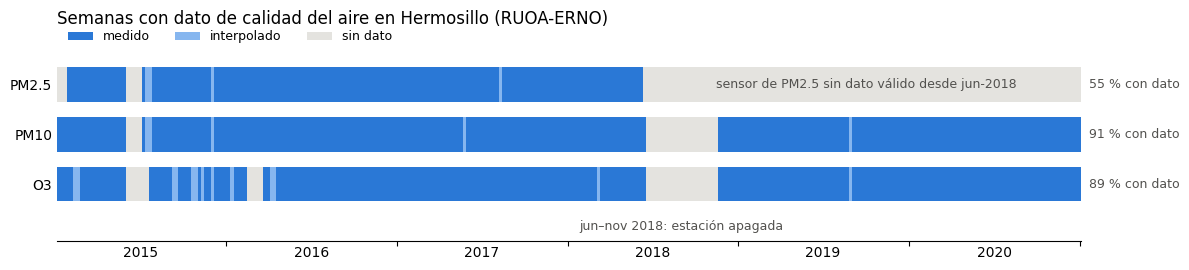

In [32]:
fig, ax = plt.subplots(figsize=(12, 2.8))
plot_cobertura(
    semanal,
    "fecha_semana",
    capas={pol: normed_col(pol) for pol in POLS},
    interpoladas={pol: f"{_PREFIX[pol]}_interpolado" for pol in POLS},
    ax=ax,
)
# Notas sobre los dos huecos que más pesan
ax.set_ylim(bottom=-1.15)
ax.text(pd.Timestamp("2019-10-01"), 2, "sensor de PM2.5 sin dato válido desde jun-2018",
        ha="center", va="center", fontsize=9, color=GRIS)
ax.text(pd.Timestamp("2018-09-01"), -0.85, "jun–nov 2018: estación apagada",
        ha="center", va="center", fontsize=9, color=GRIS)
ax.set_title("Semanas con dato de calidad del aire en Hermosillo (RUOA-ERNO)", loc="left", pad=22)
plt.tight_layout()
plt.show()

In [33]:
# Semanas con dato (medido o interpolado) por año, por contaminante y en combinación
con_dato = pd.DataFrame({pol: semanal[normed_col(pol)].notna() for pol in POLS})
con_dato["PM10 y O3"] = con_dato["PM10"] & con_dato["O3"]
con_dato["los tres"] = con_dato[POLS].all(axis=1)
cobertura = con_dato.groupby(semanal["anio"]).sum()
cobertura.insert(0, "semanas", semanal.groupby("anio").size())
cobertura.loc["2015–2019"] = cobertura.loc[2015:2019].sum()  # sin 2020, año atípico por COVID-19
cobertura

,semanas,PM2.5,PM10,O3,PM10 y O3,los tres
anio,,,,,,
2015,52,44,47,45,45,42
2016,52,52,52,47,47,47
2017,52,52,52,52,52,52
2018,52,23,30,30,30,23
2019,52,0,52,52,52,0
2020,53,0,53,53,53,0
2015–2019,260,171,233,226,226,164


### 8.2 Series semanal y mensual

Serie semanal y mensual de la métrica normada. Los círculos blancos son los
valores interpolados y los huecos de la línea son los NaN largos que se
decidieron no rellenar. La línea punteada es el límite **diario** de
la NOM: un promedio semanal o mensual por debajo no quiere decir que ningún día
lo rebasó (para eso está `*_dias_excede_nom`).

**Resultado:** La serie semanal y la mensual se mueven juntas y muestran una estacionalidad clara: PM10 (y en menor medida PM2.5) sube en invierno y baja en verano; O3 sube en primavera (abril–mayo) y baja en invierno. Los promedios quedan bajo la NOM, salvo una semana de PM10 a fines de noviembre de 2017 (84 µg/m³). En días sueltos, PM10 rebasa la NOM de 2 a 14 días por año; PM2.5 y O3 solo un día cada uno en toda la serie. Los valores interpolados siguen la tendencia de sus vecinos, sin saltos.

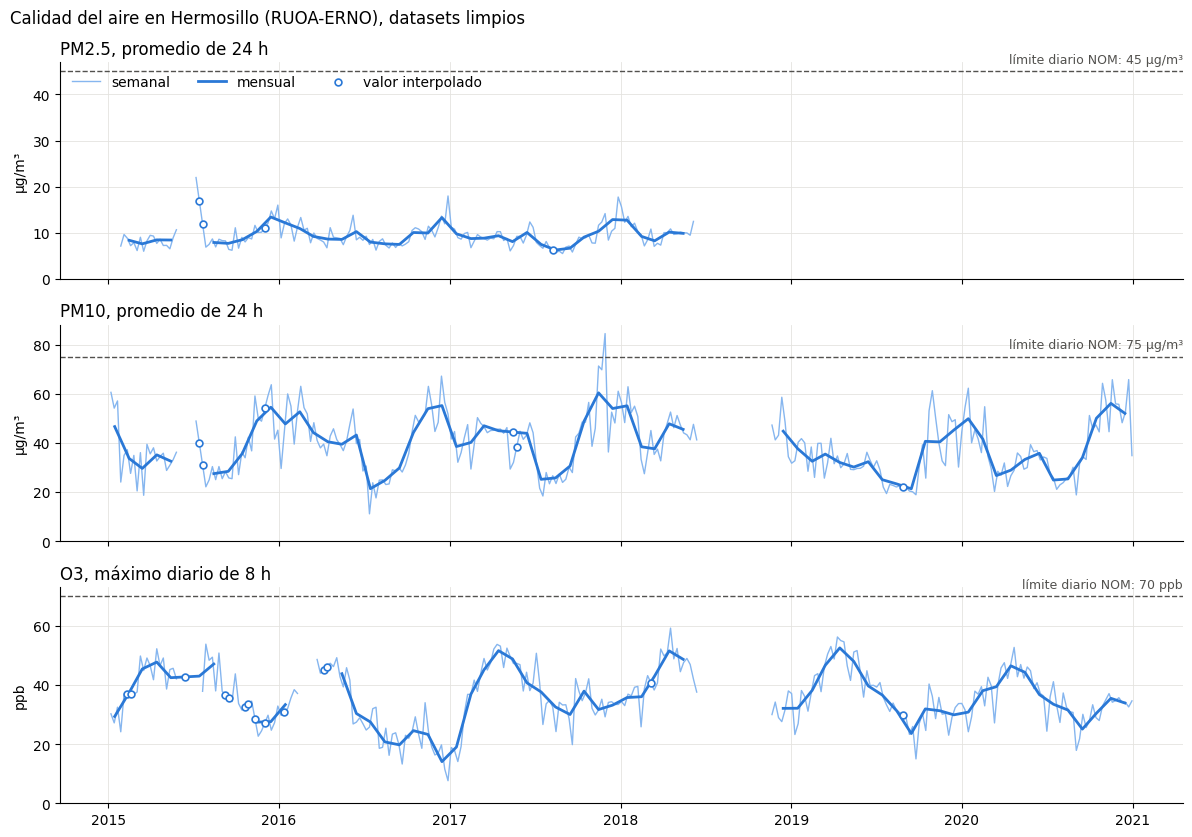

In [34]:
METRICA = {
    "PM2.5": ("PM2.5, promedio de 24 h", "µg/m³"),
    "PM10": ("PM10, promedio de 24 h", "µg/m³"),
    "O3": ("O3, máximo diario de 8 h", "ppb"),
}

fig, axes = plt.subplots(len(POLS), 1, figsize=(12, 8.5), sharex=True)
for ax, pol in zip(axes, POLS):
    c = normed_col(pol)
    titulo, unidad = METRICA[pol]
    # Cada periodo se dibuja a la mitad de su duración (miércoles / día 15)
    ax.plot(semanal["fecha_semana"] + pd.Timedelta(days=3), semanal[c],
            color=AZUL_CLARO, lw=1, label="semanal")
    ax.plot(mensual["fecha_mes"] + pd.Timedelta(days=14), mensual[c],
            color=AZUL, lw=2, label="mensual")
    # Valores interpolados: círculo blanco con borde azul
    for tabla, fecha, mitad in [(semanal, "fecha_semana", 3), (mensual, "fecha_mes", 14)]:
        interp = tabla[f"{_PREFIX[pol]}_interpolado"]
        ax.scatter(tabla.loc[interp, fecha] + pd.Timedelta(days=mitad), tabla.loc[interp, c],
                   s=24, facecolor="white", edgecolor=AZUL, linewidth=1.2, zorder=3,
                   label="valor interpolado" if fecha == "fecha_semana" else "_nolegend_")
    limite = AIR_QUALITY_NOM_LIMITS[pol]
    ax.axhline(limite, color=GRIS, ls="--", lw=1)
    ax.annotate(f"límite diario NOM: {limite:g} {unidad}", xy=(1, limite), xycoords=("axes fraction", "data"),
                xytext=(0, 4), textcoords="offset points", ha="right", va="bottom", color=GRIS, fontsize=9)
    ax.set_title(titulo, loc="left")
    ax.set_ylabel(unidad)
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper left", frameon=False, ncols=3)
fig.suptitle("Calidad del aire en Hermosillo (RUOA-ERNO), datasets limpios", x=0.01, ha="left")
plt.tight_layout()
plt.show()

Días sobre la NOM por año, contra los días válidos (de la serie diaria):

In [35]:
anio_dia = diario["fecha"].dt.year.rename("anio")
pd.concat(
    {
        pol: pd.DataFrame(
            {
                "días válidos": diario[normed_col(pol)].notna().groupby(anio_dia).sum(),
                "días sobre la NOM": (diario[normed_col(pol)] > AIR_QUALITY_NOM_LIMITS[pol]).groupby(anio_dia).sum(),
            }
        )
        for pol in POLS
    },
    axis=1,
)

PM2.5                           PM10                    \
     días válidos días sobre la NOM días válidos días sobre la NOM   
anio                                                                 
2015          297                 1          324                12   
2016          363                 0          364                 6   
2017          361                 0          356                14   
2018          165                 0          213                 2   
2019            0                 0          363                 2   
2020            0                 0          364                12   

               O3                    
     días válidos días sobre la NOM  
anio                                 
2015          298                 0  
2016          320                 0  
2017          365                 0  
2018          211                 1  
2019          361                 0  
2020          366                 0

### 8.3 Nivel del aire a lo largo del año

Porcentaje de días de cada categoría AIRE Y SALUD por mes del año (todos los
años juntos), con los colores oficiales de la NOM (tabla 11). Solo cuentan los
días con dato.

**Resultado:** Hay dos temporadas de aire peor, cada una por un contaminante distinto. **PM10, de octubre a enero:** la mitad de los días de noviembre y diciembre son Aceptable o peor (51 y 50 %) y 1 de cada 10 es Mala; de julio a septiembre, solo 0–4 %. **O3, en primavera:** 66 % de los días de abril y 45–48 % de marzo y mayo son Aceptable, aunque casi nunca Mala. Combinados, abril es el mes con más días que no son Buena (71 %), seguido de noviembre y diciembre (52 %); agosto y septiembre son los más limpios (21 y 11 %). La temporada de PM10 es la que conviene contrastar con los casos de IRA de invierno.

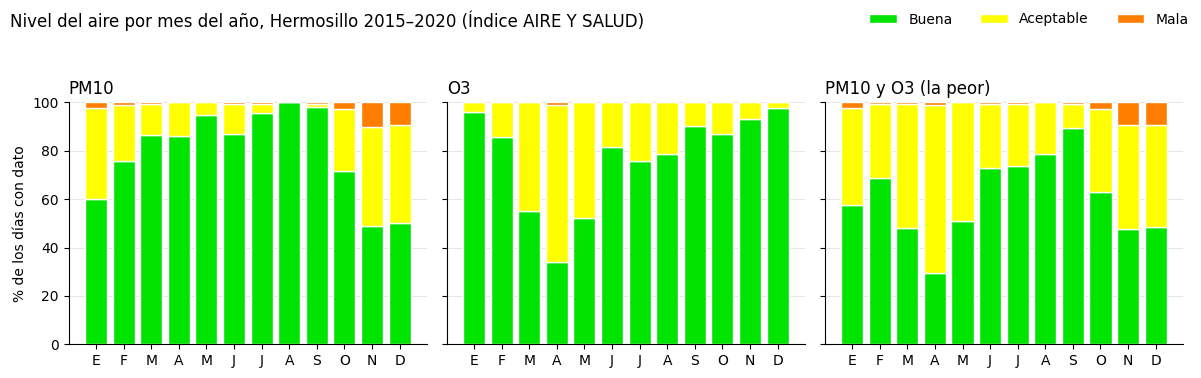

In [36]:
PANELES = {"PM10": "pm10_categoria", "O3": "o3_categoria", "PM10 y O3 (la peor)": "pm10_o3_categoria"}
MESES = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
mes = diario["fecha"].dt.month.rename("mes")
presentes = [c for c in CATEGORIAS if diario[list(PANELES.values())].eq(c).any().any()]

fig, axes = plt.subplots(1, len(PANELES), figsize=(12, 3.8), sharey=True)
for ax, (titulo, c) in zip(axes, PANELES.items()):
    pct = pd.crosstab(mes, diario[c], normalize="index").reindex(columns=presentes, fill_value=0) * 100
    abajo = np.zeros(len(pct))
    for cat in presentes:
        ax.bar(pct.index, pct[cat], bottom=abajo, width=0.8, color=AIR_QUALITY_CATEGORY_COLORS[cat],
               edgecolor="white", linewidth=1, label=cat)
        abajo += pct[cat].to_numpy()
    ax.set_title(titulo, loc="left")
    ax.set_xticks(range(1, 13), MESES)
    ax.set_ylim(0, 100)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% de los días con dato")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=len(presentes), frameon=False)
fig.suptitle("Nivel del aire por mes del año, Hermosillo 2015–2020 (Índice AIRE Y SALUD)", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

In [37]:
# % de días Aceptable o peor por mes del año
pd.DataFrame(
    {
        titulo: diario[c].ne("Buena").astype(float).where(diario[c].notna())
        .groupby(mes).mean().mul(100).round(0)
        for titulo, c in PANELES.items()
    }
).T.set_axis(MESES, axis=1)

,E,F,M,A,M,J,J,A,S,O,N,D
PM10,40.0,24.0,14.0,14.0,5.0,13.0,4.0,0.0,2.0,28.0,51.0,50.0
O3,4.0,14.0,45.0,66.0,48.0,18.0,24.0,21.0,10.0,13.0,7.0,2.0
PM10 y O3 (la peor),43.0,31.0,52.0,71.0,49.0,27.0,26.0,21.0,11.0,37.0,52.0,52.0


## 9. Guardar salida

La serie diaria es un paso intermedio y va a `data/interim/aire/`; los datasets
limpios semanal y mensual van a `data/processed/aire/`.

In [38]:
salidas = {DAILY_PATH: diario, WEEKLY_PATH: semanal, MONTHLY_PATH: mensual}
for ruta, tabla in salidas.items():
    ruta.parent.mkdir(parents=True, exist_ok=True)
    tabla.to_csv(ruta, index=False)
    print(f"{len(tabla):>5} filas × {tabla.shape[1]:>2} columnas -> {ruta.relative_to(PROJ_ROOT)}")

# Comprobación: lo guardado se lee igual que lo que hay en memoria, con los mismos
# tipos de columna. Todos los faltantes son NaN (no hay <NA> ni None), en memoria y
# en el CSV: en columnas numéricas (float64) y en las de texto (categorías).
for ruta, tabla in salidas.items():
    fecha = tabla.columns[0]
    leido = pd.read_csv(ruta, parse_dates=[fecha])
    pd.testing.assert_frame_equal(leido, tabla)
    tipos_na = {str(tabla[c].dtype) for c in tabla.columns if tabla[c].isna().any()}
    assert tipos_na <= {"float64", "object"}, f"{ruta.name}: faltantes con tipos {tipos_na}"
    texto = tabla.select_dtypes("object")
    assert not texto.map(lambda v: v is None or v is pd.NA).any().any(), f"{ruta.name}: None o <NA>"
print("Lectura de vuelta: OK; los faltantes son NaN en todas las tablas")

 2192 filas × 18 columnas -> data/interim/aire/aire_hermosillo_diario.csv
  313 filas × 29 columnas -> data/processed/aire/aire_hermosillo_semanal.csv
   72 filas × 26 columnas -> data/processed/aire/aire_hermosillo_mensual.csv
Lectura de vuelta: OK; los faltantes son NaN en todas las tablas


## Diccionario de columnas (semanal y mensual)

Las dos tablas tienen las mismas métricas; cambia la llave de tiempo.

| Columna | Descripción |
|---------|-------------|
| `fecha_semana` | (semanal) Domingo de inicio de la semana epidemiológica |
| `anio`, `semana` | (semanal) Año y semana epidemiológicos, como en los casos de IRA |
| `n_dias` | (semanal) Días de la semana dentro de la serie: 7, salvo la SE 53 de 2020 (5) |
| `fecha_mes` | (mensual) Primer día del mes |
| `pm25_ugm3`, `pm10_ugm3` | Media de los promedios diarios de 24 h (µg/m³) |
| `pm25_max_diario_ugm3`, `pm10_max_diario_ugm3` | Promedio de 24 h del peor día del periodo (µg/m³) |
| `o3_ppb` | Media de los promedios diarios de 24 h de O3 (ppb) |
| `o3_max8h_ppb` | Media del máximo diario del promedio móvil de 8 h (ppb); **métrica normada de O3** |
| `o3_max8h_max_ppb` | Máximo de 8 h del peor día del periodo (ppb) |
| `*_dias_excede_nom` | Días sobre el límite diario de la NOM (PM2.5 45, PM10 75 µg/m³; O3 70 ppb). Es número decimal (`2.0`) para que su faltante también sea `NaN` |
| `*_categoria_peor_dia` | Categoría AIRE Y SALUD (NOM-172-SEMARNAT-2019) del peor día del periodo: Buena, Aceptable, Mala, Muy mala o Extremadamente mala |
| `*_dias_aceptable_o_peor` | Días del periodo en Aceptable o peor. Los días Mala o peor de PM son `*_dias_excede_nom`; en O3 pueden ser más, porque cuenta también el máximo de 1 h |
| `*_dias_validos` | Días medidos con la métrica normada válida; decide la suficiencia |
| `*_interpolado` | `True` si los promedios de ese periodo se interpolaron (hueco de ≤ 2 semanas o de 1 mes) |
| `pm10_o3_categoria_peor_dia`, `pm10_o3_dias_aceptable_o_peor`, `pm10_o3_dias_validos` | Lo mismo para la peor de PM10 y O3 de cada día; cuentan solo los días con los dos |

La tabla diaria (`data/interim/aire/`) trae la categoría de cada día en
`pm25_categoria`, `pm10_categoria`, `o3_categoria` y `pm10_o3_categoria`. Las
categorías se guardan como texto; para ordenarlas o graficarlas en orden:
`pd.Categorical(serie, categories=AIR_QUALITY_CATEGORIES, ordered=True)`.

Todos los faltantes son `NaN`, el mismo valor en memoria y al leer el CSV (no
hay `<NA>`). Un periodo sin suficiencia tiene NaN en todas sus métricas de ese
contaminante, pero conserva `*_dias_validos` para saber por qué. Si además
está en un hueco corto, sus promedios se interpolan (`*_interpolado = True`);
sus máximos y `*_dias_excede_nom` siguen en NaN.

## Decisiones de procesamiento

Si una decisión cambia los datasets, se implementa en
`sonora_health_climate_eda/aire.py` (constantes en `config.py`, sección Capa 4).

| Tema | Decisión | Por qué |
|------|----------|---------|
| Banderas `OR` y `OS` | NaN | Valores imposibles o sin valor |
| Banderas `BDL` | Mitad del límite de detección (2 µg/m³ PM, 0.5 ppb O3) | RUOA reporta ceros y negativos; LD/2 es la sustitución estándar |
| O3 > 120 ppb | NaN | Mesetas de ~400 ppb: artefacto del equipo (P99.9 ≈ 76 ppb) |
| PM2.5 > PM10 + 10 µg/m³ | NaN en PM2.5 | Físicamente imposible |
| PM altos (tolvaneras) | Se conservan | Son plausibles en Hermosillo y son exposición real |
| Suficiencia | 75 %: 18 h por día, 6 de 7 días por semana, 75 % de días por mes | Criterio de las NOM; la semana cambia poco con 5 o 7 días (sección 6) |
| Días con ≥ 75 % de horas BDL | NaN | Sensor plano en cero (sobre todo PM2.5 en 2019), no aire limpio |
| Huecos cortos (≤ 2 semanas; 1 mes) | Interpolación lineal de los promedios, marcada en `*_interpolado` | Error de 12–16 % de la media, contra 19–26 % de rellenar con la media (sección 6.1); evita cortes en las gráficas y en las comparaciones con las semanas anteriores |
| Huecos largos | Sin imputación; NaN + `*_dias_validos` | Casi todo lo que falta está en huecos de más de 30 días (sección 5); rellenarlos borraría el ciclo estacional |
| PM2.5 2018-06 a 2020-12 | Sin dato; usar PM10 como indicador de partículas | Estimar PM2.5 desde PM10 no aporta información nueva |
| Jun–nov 2018 | Sin dato en los tres contaminantes | Falla de toda la estación; las comparaciones usan solo los periodos con dato y dicen cuántos entran (sección 8.1) |
| Nivel del aire | Índice AIRE Y SALUD con las bandas de la NOM-172-SEMARNAT-2019, por día; semanas y meses guardan el peor día y los días Aceptable o peor | El límite de "Aceptable" de 2019 es el de las NOM vigentes en 2015–2020; clasificar el promedio esconde los días malos (sección 6.2) |
| Índice combinado | Solo PM10 y O3 (`pm10_o3_*`) | PM2.5 falta desde 2018; con él, el índice mejoraría solo por dejar de medirlo |
| Semana | Epidemiológica (domingo a sábado), 313 semanas | Empata con las semanas de IRA y de Open-Meteo (2.1) |
| SE 53 de 2020 | Se conserva con 5 días y suficiencia sobre esos 5 | La serie termina el 31 de diciembre |